# Step 4: Explore

Which fields carry Norway's liquids production today, which have peaked, and which are still ramping up.

In [10]:
from getpass import getpass

import pandas as pd
from sqlalchemy import URL, create_engine, text

# Connect straight to the project database; the password is asked for, never stored
db_url = URL.create(
    "mysql+pymysql",
    username="root",
    password=getpass("MySQL root password: "),
    host="localhost",
    port=3306,
    database="norway_forecast",
)
db = create_engine(db_url)

# Quick check that the silver view is reachable
with db.connect() as conn:
    row_count = conn.execute(text("SELECT COUNT(*) FROM silver_field_production_rates")).scalar()
print(f"Connected. Silver view has {row_count:,} rows")

Connected. Silver view has 28,455 rows


In [11]:
# Average liquids rate per field over the latest 12 months in the data.
# Dividing the sum by 12 (not AVG) counts months without a row as zero,
# so a field that started mid-window is not overstated.
latest_12_months_by_field = """
SELECT
    field_name,
    SUM(liquids_kbd) / 12 AS liquids_kbd
FROM silver_field_production_rates
WHERE production_month > (
    SELECT MAX(production_month) - INTERVAL 12 MONTH
    FROM silver_field_production_rates
)
GROUP BY field_name
ORDER BY liquids_kbd DESC
"""
fields_now = pd.read_sql(text(latest_12_months_by_field), db)

print(f"{len(fields_now)} fields reported in the window, "
      f"total {fields_now['liquids_kbd'].sum():,.1f} kb/d")
fields_now.head(15)

109 fields reported in the window, total 2,100.5 kb/d


,field_name,liquids_kbd
0,JOHAN SVERDRUP,666.5
1,JOHAN CASTBERG,179.6
2,SNORRE,80.9
3,BALDER,74.4
4,BREIDABLIKK,67.5
5,ÅSGARD,58.7
6,EKOFISK,48.8
7,TROLL,39.4
8,ELDFISK,38.5
9,GULLFAKS SØR,33.9


In [12]:
# How concentrated is production? Each field's share of the national total,
# and the running total of shares going down the ranked list.
national_total = fields_now["liquids_kbd"].sum()
fields_now["share_pct"] = fields_now["liquids_kbd"] / national_total * 100
fields_now["cumulative_share_pct"] = fields_now["share_pct"].cumsum()

# Number of fields needed to reach 50%, 80% and 90% of national liquids
for threshold in [50, 80, 90]:
    n_fields = (fields_now["cumulative_share_pct"] < threshold).sum() + 1
    print(f"{n_fields:>3} fields make up {threshold}% of liquids")

fields_now.head(15).round(1)

  5 fields make up 50% of liquids
 26 fields make up 80% of liquids
 39 fields make up 90% of liquids


,field_name,liquids_kbd,share_pct,cumulative_share_pct
0,JOHAN SVERDRUP,666.5,31.7,31.7
1,JOHAN CASTBERG,179.6,8.6,40.3
2,SNORRE,80.9,3.8,44.1
3,BALDER,74.4,3.5,47.7
4,BREIDABLIKK,67.5,3.2,50.9
5,ÅSGARD,58.7,2.8,53.7
6,EKOFISK,48.8,2.3,56.0
7,TROLL,39.4,1.9,57.9
8,ELDFISK,38.5,1.8,59.7
9,GULLFAKS SØR,33.9,1.6,61.3


In [13]:
# Show decimals with 1 digit in tables (display only; the data keeps full precision)
pd.set_option("display.precision", 1)

# Monthly liquids rate for every field; parse_dates reads the column as real dates this time
monthly = pd.read_sql(
    text("SELECT field_name, production_month, liquids_kbd FROM silver_field_production_rates"),
    db,
    parse_dates=["production_month"],
)

# Reshape: one row per month, one column per field (like a spreadsheet).
# A month with no row for a field becomes 0: nothing reported, nothing produced.
liquids_by_field = (
    monthly
    .pivot_table(index="production_month", columns="field_name", values="liquids_kbd", fill_value=0)
    .asfreq("MS", fill_value=0)   # make sure every calendar month exists ("MS" = month start)
)

print(liquids_by_field.shape)
print(liquids_by_field.index.min().date(), "to", liquids_by_field.index.max().date())
liquids_by_field[["JOHAN SVERDRUP", "JOHAN CASTBERG", "EKOFISK"]].tail()


(662, 136)
1971-06-01 to 2026-07-01


field_name,JOHAN SVERDRUP,JOHAN CASTBERG,EKOFISK
production_month,,,
2026-03-01,676.0,204.6,41.1
2026-04-01,663.1,203.7,47.0
2026-05-01,655.3,214.2,46.8
2026-06-01,636.4,153.8,43.0
2026-07-01,609.8,120.0,44.6


In [14]:
# Average of the latest 12 months, recalculated at every month
rolling_12m = liquids_by_field.rolling(12).mean()
latest_month = rolling_12m.index.max()

field_stage = pd.DataFrame({
    "peak_month": rolling_12m.idxmax(),     # month the smoothed rate was highest
    "peak_kbd": rolling_12m.max(),
    "current_kbd": rolling_12m.iloc[-1],    # last row = the 12 months ending July 2026
})
field_stage["pct_of_peak"] = field_stage["current_kbd"] / field_stage["peak_kbd"] * 100

field_stage.sort_values("current_kbd", ascending=False).head(15)


,peak_month,peak_kbd,current_kbd,pct_of_peak
field_name,,,,
JOHAN SVERDRUP,2024-04-01,741.8,666.5,89.8
JOHAN CASTBERG,2026-06-01,187.0,179.6,96.0
SNORRE,2003-10-01,252.9,80.9,32.0
BALDER,2006-01-01,121.3,74.4,61.3
BREIDABLIKK,2026-01-01,77.4,67.5,87.3
ÅSGARD,2003-08-01,259.5,58.7,22.6
EKOFISK,2003-05-01,316.4,48.8,15.4
TROLL,2003-05-01,396.1,39.4,9.9
ELDFISK,1980-11-01,109.3,38.5,35.2


In [15]:
def classify_stage(field):
    """Production stage of one field, based on its 12-month average rate."""
    if field["current_kbd"] <= 0:
        return "not producing"
    if field["pct_of_peak"] < 85:
        return "declining"
    if field["peak_month"] > latest_month - pd.DateOffset(months=12):
        return "ramping up / at peak"
    return "plateau"

field_stage["stage"] = field_stage.apply(classify_stage, axis=1)

# Fields and liquids per stage
stage_summary = field_stage.groupby("stage").agg(
    n_fields=("current_kbd", "size"),
    liquids_kbd=("current_kbd", "sum"),
)
stage_summary["share_pct"] = stage_summary["liquids_kbd"] / stage_summary["liquids_kbd"].sum() * 100
stage_summary.sort_values("liquids_kbd", ascending=False)


,n_fields,liquids_kbd,share_pct
stage,,,
declining,88,1084.8,51.6
plateau,2,690.6,32.9
ramping up / at peak,7,325.1,15.5
not producing,39,0.0,0.0


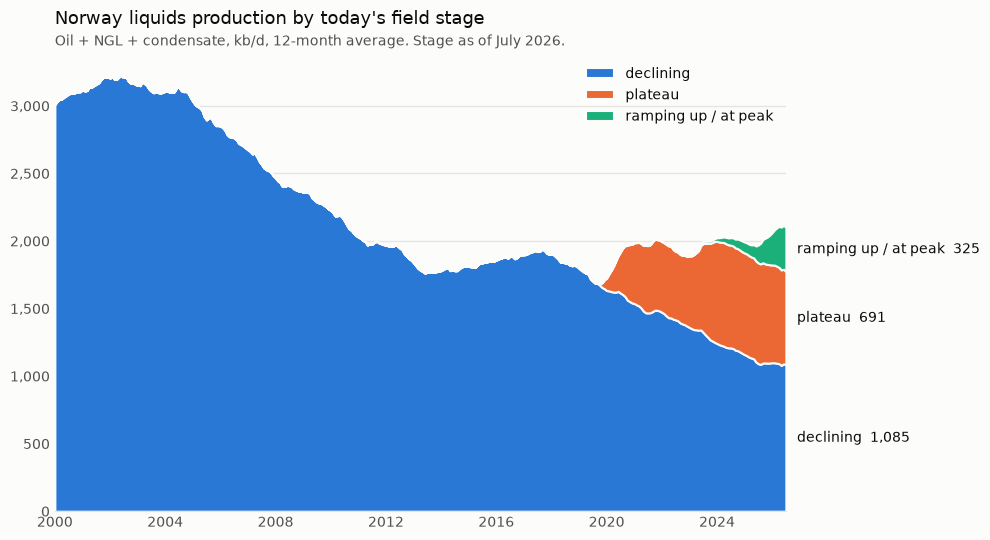

In [16]:
import matplotlib.pyplot as plt
from matplotlib.ticker import StrMethodFormatter

# Fixed order and colors: each stage keeps its color in every chart of this project
STAGE_ORDER = ["declining", "plateau", "ramping up / at peak"]
STAGE_COLORS = {"declining": "#2a78d6", "plateau": "#eb6834", "ramping up / at peak": "#1baf7a"}
SURFACE, TEXT_PRIMARY, TEXT_SECONDARY, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e6e5e1"

# Add up the 12-month average of all fields in each stage, for every month
liquids_by_stage = rolling_12m.T.groupby(field_stage["stage"]).sum().T
liquids_by_stage = liquids_by_stage.loc["2000-01-01":, STAGE_ORDER]

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.stackplot(
    liquids_by_stage.index,
    [liquids_by_stage[stage] for stage in STAGE_ORDER],
    labels=STAGE_ORDER,
    colors=[STAGE_COLORS[stage] for stage in STAGE_ORDER],
    edgecolor=SURFACE, linewidth=1.5,   # thin light line separates the bands
)

# Label each band at the right edge with its latest value
latest = liquids_by_stage.iloc[-1]
band_bottom = 0
for stage in STAGE_ORDER:
    ax.annotate(
        f"{stage}  {latest[stage]:,.0f}",
        xy=(liquids_by_stage.index[-1], band_bottom + latest[stage] / 2),
        xytext=(8, 0), textcoords="offset points", va="center",
        color=TEXT_PRIMARY, fontsize=10, annotation_clip=False,
    )
    band_bottom += latest[stage]

# Title, subtitle with units, and a quiet frame
ax.set_title("Norway liquids production by today's field stage",
             loc="left", color=TEXT_PRIMARY, fontsize=13, pad=22)
ax.text(0, 1.02, "Oil + NGL + condensate, kb/d, 12-month average. Stage as of July 2026.",
        transform=ax.transAxes, color=TEXT_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_xlim(liquids_by_stage.index[0], liquids_by_stage.index[-1])
ax.set_ylim(0)
ax.legend(loc="upper right", frameon=False, labelcolor=TEXT_PRIMARY)

fig.tight_layout()
plt.show()


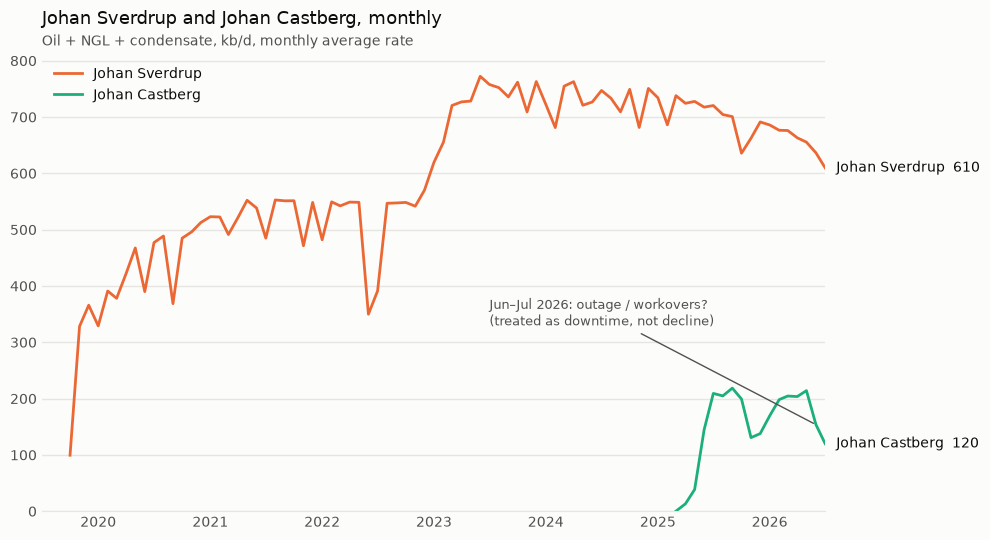

In [17]:
# The two fields that drive the outlook, colored by their stage (same colors as cell 7)
FIELDS = {"JOHAN SVERDRUP": "plateau", "JOHAN CASTBERG": "ramping up / at peak"}
big_two = liquids_by_field.loc["2019-07-01":, list(FIELDS)]

fig, ax = plt.subplots(figsize=(10, 5.5), facecolor=SURFACE)
ax.set_facecolor(SURFACE)

for field, stage in FIELDS.items():
    series = big_two[field]
    producing = series[series.cumsum() > 0]   # start the line at first production
    ax.plot(producing.index, producing, color=STAGE_COLORS[stage], linewidth=2, label=field.title())
    # Label the line end with the field name and its latest month
    ax.annotate(
        f"{field.title()}  {producing.iloc[-1]:,.0f}",
        xy=(producing.index[-1], producing.iloc[-1]),
        xytext=(8, 0), textcoords="offset points", va="center",
        color=TEXT_PRIMARY, fontsize=10, annotation_clip=False,
    )

# Note on the Castberg drop, with a thin line pointing at June 2026
ax.annotate(
    "Jun–Jul 2026: outage / workovers?\n(treated as downtime, not decline)",
    xy=(pd.Timestamp("2026-06-01"), big_two.loc["2026-06-01", "JOHAN CASTBERG"]),
    xytext=(pd.Timestamp("2023-07-01"), 330), textcoords="data",
    color=TEXT_SECONDARY, fontsize=9,
    arrowprops=dict(arrowstyle="-", color=TEXT_SECONDARY, linewidth=1),
)

ax.set_title("Johan Sverdrup and Johan Castberg, monthly",
             loc="left", color=TEXT_PRIMARY, fontsize=13, pad=22)
ax.text(0, 1.02, "Oil + NGL + condensate, kb/d, monthly average rate",
        transform=ax.transAxes, color=TEXT_SECONDARY, fontsize=10)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
ax.grid(axis="y", color=GRID, linewidth=1)
ax.set_axisbelow(True)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=TEXT_SECONDARY, length=0)
ax.set_xlim(big_two.index[0], big_two.index[-1])
ax.set_ylim(0)
ax.legend(loc="upper left", frameon=False, labelcolor=TEXT_PRIMARY)

fig.tight_layout()
plt.show()


In [20]:
# Save the stage table so the forecast notebook (05) can use it.
# reset_index() turns field_name into a normal column; MySQL can't index a TEXT column.
field_stage.reset_index().to_sql("field_stage", db, if_exists="replace", index=False)
print(f"Saved {len(field_stage)} fields to MySQL table field_stage")



Saved 136 fields to MySQL table field_stage
